In [54]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display
import unicodedata
import matplotlib.pyplot as plt

In [55]:
REQUIRED_FILES = (
    "Afluencia Diaria del Metro (Desglosada).csv",
    "Afluencia Diaria del Metrobús (Desglosada).csv",
    "Afluencia Preliminar en Transporte Publico (histórico).csv",
    "Diccionario Afluencia Desglosada - MB.csv",
    "Diccionario de datos (Afluencia desglosada).csv",
    "Diccionario de datos ingresos STCM.xlsx",
    "Ingresos del Sistema de Transporte Colectivo Metro.csv",
    "Viajes diarios del sistema Ecobici.csv",
    "Viajes Ecobico 2026-01.csv",
    "Viajes mensuales desglosados del sistema Ecobici.csv",
)

def localizar_datos() -> Path:
    """Devuelve la carpeta datasets/ de Movilidad-Urbana-del-Sistema-de-Transporte-CDMX o indica cómo prepararla."""
    candidatos = []
    definida = os.environ.get("MOVILIDAD_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())

    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
            base / "Datasets",
            base.parent / "Movilidad-Urbana-del-Sistema-de-Transporte-CDMX" / "Datasets",
        ])

    for ruta in candidatos:
        if ruta.is_dir() and all((ruta / nombre).is_file() for nombre in REQUIRED_FILES):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV de Movilidad-Urbana. Ejecuta 'git clone "
        "https://github.com/Juan-Gallegos7/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX' en la "
        "carpeta del curso y coloca este notebook en una carpeta hermana "
        "del repositorio; o establece MOVILIDAD_DATA_DIR con la ruta a datasets/."
    )


DATA_DIR = localizar_datos()
print("Datos encontrados en:", DATA_DIR)

Datos encontrados en: /Users/arantxaalva21/Diplomado_2026/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX/Datasets


In [56]:
ruta = Path("C:/Users/ricar/iCloudDrive/Diplomado_Modelos_Est_y_Mat/Modulo_1/Proyecto/Movilidad-Urbana-del-Sistema-de-Transporte-CDMX/Datasets")
for nombre in REQUIRED_FILES:
    existe = ( ruta / nombre).is_file()
    print(nombre, "->", existe)

Afluencia Diaria del Metro (Desglosada).csv -> False
Afluencia Diaria del Metrobús (Desglosada).csv -> False
Afluencia Preliminar en Transporte Publico (histórico).csv -> False
Diccionario Afluencia Desglosada - MB.csv -> False
Diccionario de datos (Afluencia desglosada).csv -> False
Diccionario de datos ingresos STCM.xlsx -> False
Ingresos del Sistema de Transporte Colectivo Metro.csv -> False
Viajes diarios del sistema Ecobici.csv -> False
Viajes Ecobico 2026-01.csv -> False
Viajes mensuales desglosados del sistema Ecobici.csv -> False


In [57]:

import chardet

with open(
    DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv",
    "rb"
) as f:
    resultado = chardet.detect(f.read(100000))

print(resultado)

{'encoding': 'utf-8', 'confidence': 0.9041276, 'language': 'pt', 'mime_type': 'text/plain'}


In [58]:
Afluencia_Metro = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv")
Afluencia_Metrobus = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metrobús (Desglosada).csv")
Afluencia_TP_historico = pd.read_csv(DATA_DIR / "Afluencia Preliminar en Transporte Publico (histórico).csv")
Ingresos_SCTM = pd.read_csv(DATA_DIR / "Ingresos del Sistema de Transporte Colectivo Metro.csv")
#Dic_Afluencia = pd.read_csv(DATA_DIR / "Diccionario Afluencia Desglosada - MB.csv", encoding="ISO-8859-1")
#Dic_datos_Afluencia = pd.read_csv(DATA_DIR / "Diccionario de datos (Afluencia desglosada).csv", encoding="ISO-8859-1")
Dic_ingresos_SCTM = pd.read_excel(DATA_DIR / "Diccionario de datos ingresos STCM.xlsx")
#Viajes_Ecobici_202601 = pd.read_csv(DATA_DIR / "Viajes Ecobico 2026-01.csv")
#Viajes_Ecobici_mensual = pd.read_csv(DATA_DIR / "Viajes mensuales desglosados del sistema Ecobici.csv")

for nombre, tabla in {
    "Afluencia_Metro": Afluencia_Metro,
    "Afluencia_Metrobus": Afluencia_Metrobus,
    "Afluencia_TP_historico": Afluencia_TP_historico,
    #"Dic_Afluencia": Dic_Afluencia,
    #"Dic_datos_Afluencia": Dic_datos_Afluencia,
    "Dic_ingresos_SCTM": Dic_ingresos_SCTM,
    "Ingresos_SCTM": Ingresos_SCTM,
    #"Viajes_Ecobici_202601": Viajes_Ecobici_202601,
    #"Viajes_Ecobici_mensual": Viajes_Ecobici_mensual,
}.items():
    print(f"{nombre:12s}: {len(tabla):>8,} filas × {tabla.shape[1]:>2} columnas")

display(Afluencia_Metro.head(3))
display(Afluencia_Metrobus.head(3))
display(Afluencia_TP_historico.head(3))
#display(Dic_Afluencia.head())
#display(Dic_datos_Afluencia.head())
display(Dic_ingresos_SCTM.head())
display(Ingresos_SCTM.head(3))
#display(Viajes_Ecobici_202601.head(3))
#display(Viajes_Ecobici_mensual.head(3))

Afluencia_Metro: 1,227,915 filas ×  7 columnas
Afluencia_Metrobus:   29,386 filas ×  6 columnas
Afluencia_TP_historico:   18,714 filas ×  8 columnas
Dic_ingresos_SCTM:       14 filas ×  3 columnas
Ingresos_SCTM:  159,948 filas ×  4 columnas


,fecha,mes,anio,linea,estacion,tipo_pago,afluencia
0,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Boleto,1848
1,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Prepago,790
2,2021-01-01,Enero,2021,LÃ­nea 1,Balbuena,Gratuidad,325


,fecha,mes,anio,linea,tipo_pago,afluencia
0,2021-01-01,Enero,2021,Línea 1,Prepago,39122.0
1,2021-01-01,Enero,2021,Línea 1,Gratuidad,3528.0
2,2021-01-01,Enero,2021,Línea 2,Prepago,23669.0


,id,organismo,linea_servicio,dia,fecha,afluencia_tarjeta,afluencia_boleto,afluencia_total_preliminar
0,1,Ecobici,NaN,Domingo,2020-03-01,NaN,NaN,"11,238"
1,2,Ecobici,NaN,Lunes,2020-03-02,NaN,NaN,"29,475"
2,3,Ecobici,NaN,Martes,2020-03-03,NaN,NaN,"31,855"


,Variable,Descripción Variable,Etiqueta de Datos Abiertos
0,Fecha,Indica el día en el que se recibió este ingreso.,FECHA
1,Tipo de ingreso,Campo que especifíca si el ingreso fue por ven...,TIPO_INGRESO
2,Línea 1,Indica los ingresos que recibió la ciudad para...,LINEA_1
3,Línea 2,Indica los ingresos que recibió la ciudad para...,LINEA_2
4,Línea 3,Indica los ingresos que recibió la ciudad para...,LINEA_3


,fecha,tipo_ingreso,linea,ingreso
0,2012-01-01,Boletos,Línea 1,648825.0
1,2012-01-01,Boletos,Línea 2,657120.0
2,2012-01-01,Boletos,Línea 3,466803.0


In [59]:
display(Afluencia_Metro.isna().sum().sort_values(ascending=False).head(8).to_frame("Faltantes Metro"))
display(Afluencia_Metrobus.isna().sum().sort_values(ascending=False).head(8).to_frame("Faltantes Metrobus"))
display(Afluencia_TP_historico.isna().sum().sort_values(ascending=False).head(8).to_frame("Faltantes Historico"))

,Faltantes Metro
fecha,0
mes,0
anio,0
linea,0
estacion,0
tipo_pago,0
afluencia,0


,Faltantes Metrobus
fecha,0
mes,0
anio,0
linea,0
tipo_pago,0
afluencia,0


,Faltantes Historico
afluencia_tarjeta,16027
afluencia_boleto,15116
linea_servicio,489
afluencia_total_preliminar,202
id,0
organismo,0
dia,0
fecha,0


Dado que los valores de la variable linea están incorrectos en formato, es necesario corregir la etiqueta "LÃ­nea" por "Linea", para mantener consistencia.

In [60]:
#Afluencia_Metro["linea"]=Afluencia_Metro["linea"].str.replace("LÃ­nea","Linea", regex=False)

In [61]:
print("Registros por línea (Metro): ", Afluencia_Metro.groupby("linea").size())
print("Registros por mes (Metro): ", Afluencia_Metro.groupby("mes").size())
print("Registros por mes (Año): ", Afluencia_Metro.groupby("anio").size())
print("Registros por mes (Estacion): ", Afluencia_Metro.groupby("estacion").size())
print("Registros por mes (tipo_pago): ", Afluencia_Metro.groupby("tipo_pago").size())

Registros por línea (Metro):  linea
Linea 1      73080
Linea 12     73080
Linea 2      87696
Linea 3      76734
Linea 4      36540
Linea 5      47502
Linea 6      40194
Linea 7      51156
Linea 8      69426
Linea 9      43848
Linea A      36540
Linea B      76734
LÃ­nea 1     52860
LÃ­nea 12    52860
LÃ­nea 2     63432
LÃ­nea 3     55503
LÃ­nea 4     26430
LÃ­nea 5     34359
LÃ­nea 6     29073
LÃ­nea 7     37002
LÃ­nea 8     50217
LÃ­nea 9     31716
LÃ­nea A     26430
LÃ­nea B     55503
dtype: int64
Registros por mes (Metro):  mes
Abril         105300
Agosto        108810
Diciembre      90675
Enero         108810
Febrero        98865
Julio         108810
Junio         105300
Marzo         108810
Mayo          108810
Noviembre      87750
Octubre        90675
Septiembre    105300
dtype: int64
Registros por mes (Año):  anio
2021    213525
2022    213525
2023    213525
2024    214110
2025    213525
2026    159705
dtype: int64
Registros por mes (Estacion):  estacion
Acatitla                

Dado que los valores de la variable linea están incorrectos en formato, es necesario corregir la etiqueta "Línea" por "Linea", para mantener consistencia.

In [62]:
#Afluencia_Metrobus["linea"]=Afluencia_Metrobus["linea"].str.replace("Línea","Linea", regex=False)

In [63]:
print("Registros por línea (Metrobus): ", Afluencia_Metrobus.groupby("linea").size())
print("Registros por mes (Metrobus): ", Afluencia_Metrobus.groupby("mes").size())
print("Registros por Año (Metrobus): ", Afluencia_Metrobus.groupby("anio").size())
print("Registros por Tipo pago (Metrobus): ", Afluencia_Metrobus.groupby("tipo_pago").size())

Registros por línea (Metrobus):  linea
Linea 1     184
Linea 2     184
Linea 3     184
Linea 4     184
Linea 5     184
Linea 6     184
Linea 7     184
Línea 1    3284
Línea 2    3284
Línea 3    3284
Línea 4    3284
Línea 5    3284
Línea 6    3284
Línea 7    3284
linea 1     730
linea 2     730
linea 3     730
linea 4     730
linea 5     730
linea 6     730
linea 7     730
dtype: int64
Registros por mes (Metrobus):  mes
Abril         2520
Agosto        2604
Diciembre     2170
Enero         2604
Febrero       2366
Julio         2604
Junio         2520
Marzo         2604
Mayo          2604
Noviembre     2100
Octubre       2170
Septiembre    2520
dtype: int64
Registros por Año (Metrobus):  anio
2021    5110
2022    5110
2023    5110
2024    5124
2025    5110
2026    3822
dtype: int64
Registros por Tipo pago (Metrobus):  tipo_pago
Gratuidad    14693
Prepago      14693
dtype: int64


In [64]:
print("Registros por organismo (Metro): ", Afluencia_TP_historico.groupby("organismo").size())
print("Registros por servicio (Metro): ", Afluencia_TP_historico.groupby("linea_servicio").size())
print("Registros por dia (Año): ", Afluencia_TP_historico.groupby("dia").size())

Registros por organismo (Metro):  organismo
Ecobici             489
Metrobús           3461
RTP                3671
STC                5868
STE-Cablebús        121
STE-Tren Ligero     489
STE-Trolebús       4126
Suburbano           489
dtype: int64
Registros por servicio (Metro):  linea_servicio
Atenea                                                489
Eco Atenea                                            489
Ecobús                                                489
Expreso                                               489
Expreso Directo                                       489
L1                                                   1467
L1 Campos Revolución-Tlalpexco                        121
L1 Eje Central                                        489
L12                                                   489
L2                                                    978
L2 Eje 2 sur                                          489
L3                                                    978
L3 Eje 

# Calidad, limpieza y transformación

In [65]:
ROOT = DATA_DIR.parent
OUT_DATA = ROOT / "data" / "processed"
OUT_FIG = ROOT / "resultados" / "figuras"
OUT_TAB = ROOT / "resultados" / "tablas"
for carpeta in (OUT_DATA, OUT_FIG, OUT_TAB):
    carpeta.mkdir(parents=True, exist_ok=True)

registro = []

def log_decision(paso, tabla, variable, criterio, afectadas, accion, limitacion):
    registro.append({
        "paso": paso, "tabla": tabla, "variable": variable, "criterio": criterio,
        "filas_afectadas": int(afectadas), "accion": accion, "limitacion": limitacion,
    })

metro_raw = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metro (Desglosada).csv")
metro = metro_raw.copy()
metrobus = pd.read_csv(DATA_DIR / "Afluencia Diaria del Metrobús (Desglosada).csv")
ingresos = Ingresos_SCTM.copy()
historico = Afluencia_TP_historico.copy()
ecobici = pd.read_csv(
    DATA_DIR / "Viajes Ecobico 2026-01.csv",
    dtype={"Ciclo_Estacion_Retiro": str, "Ciclo_EstacionArribo": str},
    low_memory=False,
)

for nombre, df in {"metro": metro, "metrobus": metrobus, "ingresos": ingresos,
                   "historico": historico, "ecobici": ecobici}.items():
    print(f"{nombre:10s}: {len(df):>9,} filas × {df.shape[1]} columnas")

metro     : 1,227,915 filas × 7 columnas
metrobus  :    29,386 filas × 6 columnas
ingresos  :   159,948 filas × 4 columnas
historico :    18,714 filas × 8 columnas
ecobici   : 1,525,302 filas × 9 columnas


In [66]:
def limpieza(df, llave=None):
    filas = []
    for col in df.columns:
        s = df[col]
        filas.append({
            "variable": col,
            "tipo": str(s.dtype),
            "n_faltantes": int(s.isna().sum()),
            "pct_faltantes": round(100 * s.isna().mean(), 2),
            "n_unicos": int(s.nunique(dropna=True)),
        })
    res = pd.DataFrame(filas)
    print(f"Duplicados exactos: {df.duplicated().sum():,}", end="")
    if llave:
        print(f" | duplicados en la llave {llave}: {df.duplicated(llave).sum():,}")
    else:
        print()
    return res

print("METRO");    display(limpieza(metro, ["fecha", "linea", "estacion", "tipo_pago"]))
print("METROBÚS"); display(limpieza(metrobus, ["fecha", "linea", "tipo_pago"]))
print("INGRESOS"); display(limpieza(ingresos, ["fecha", "linea", "tipo_ingreso"]))
print("ECOBICI");  display(limpieza(ecobici))

METRO
Duplicados exactos: 0 | duplicados en la llave ['fecha', 'linea', 'estacion', 'tipo_pago']: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,object,0,0.0,2099
1,mes,object,0,0.0,12
2,anio,int64,0,0.0,6
3,linea,object,0,0.0,24
4,estacion,object,0,0.0,168
5,tipo_pago,object,0,0.0,3
6,afluencia,int64,0,0.0,48199


METROBÚS
Duplicados exactos: 0 | duplicados en la llave ['fecha', 'linea', 'tipo_pago']: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,object,0,0.0,2099
1,mes,object,0,0.0,12
2,anio,int64,0,0.0,6
3,linea,object,0,0.0,21
4,tipo_pago,object,0,0.0,2
5,afluencia,float64,0,0.0,25257


INGRESOS
Duplicados exactos: 11 | duplicados en la llave ['fecha', 'linea', 'tipo_ingreso']: 12


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,fecha,object,0,0.00,4230
1,tipo_ingreso,object,0,0.00,5
2,linea,object,0,0.00,12
3,ingreso,float64,1067,0.67,88998


ECOBICI
Duplicados exactos: 0


,variable,tipo,n_faltantes,pct_faltantes,n_unicos
0,Genero_Usuario,object,1,0.00,4
1,Edad_Usuario,float64,79,0.01,75
2,Bici,int64,0,0.00,7391
3,Ciclo_Estacion_Retiro,object,0,0.00,677
4,Fecha_Retiro,object,0,0.00,42
5,Hora_Retiro,object,0,0.00,69706
6,Ciclo_EstacionArribo,object,0,0.00,677
7,Fecha_Arribo,object,0,0.00,31
8,Hora_Arribo,object,0,0.00,70772


In [67]:
# Rangos de las variables numéricas y valores 
rangos = pd.DataFrame({
    "metro_afluencia": metro["afluencia"].describe(),
    "metrobus_afluencia": metrobus["afluencia"].describe(),
    "ingreso": ingresos["ingreso"].describe(),
    "ecobici_edad": ecobici["Edad_Usuario"].describe(),
}).round(1)
display(rangos)

print("Negativos  -> metro:", (metro["afluencia"] < 0).sum(),
      "| metrobús:", (metrobus["afluencia"] < 0).sum(),
      "| ingresos:", (ingresos["ingreso"] < 0).sum())
print("Ceros      -> metro:", f"{(metro['afluencia'] == 0).sum():,}",
      f"({100 * (metro['afluencia'] == 0).mean():.1f} % de las filas)")
print("Afluencia Metrobús no entera:", (metrobus["afluencia"] % 1 != 0).sum())

,metro_afluencia,metrobus_afluencia,ingreso,ecobici_edad
count,1227915.0,29386.0,158881.0,1525223.0
mean,5129.7,90640.8,414608.9,34.6
std,8758.5,105655.8,508479.6,9.8
min,0.0,42.0,0.0,16.0
25%,7.0,10865.0,2680.0,28.0
50%,2045.0,35209.5,233225.0,33.0
75%,6052.0,148693.8,662765.0,40.0
max,119577.0,586643.0,8337195.0,100.0


Negativos  -> metro: 0 | metrobús: 0 | ingresos: 0
Ceros      -> metro: 303,400 (24.7 % de las filas)
Afluencia Metrobús no entera: 57


In [68]:
def reparar_mojibake(texto):
    # Revierte la doble codificación UTF-8 -> Latin-1 (ej. 'PantitlÃ¡n' -> 'Pantitlán').
    if isinstance(texto, str) and ("Ã" in texto or "Â" in texto):
        try:
            return texto.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return texto
    return texto

def clave_sin_acentos(texto):
    # Clave de comparación: sin acentos, minúsculas y sin espacios extra.
    t = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return " ".join(t.lower().split())

def estandarizar_linea(texto):
    # Cualquier variante ('LÃ­nea 1', 'Linea 1', 'linea 1') -> 'Línea 1'.
    t = reparar_mojibake(texto)
    sufijo = clave_sin_acentos(t).replace("linea", "", 1).strip().upper()
    return f"Línea {sufijo}"

# Diagnóstico antes de corregir
antes = {
    "metro_lineas": metro["linea"].nunique(),
    "metro_estaciones": metro["estacion"].nunique(),
    "metrobus_lineas": metrobus["linea"].nunique(),
    "ingresos_tipos": ingresos["tipo_ingreso"].nunique(),
}
n_mojibake = metro["estacion"].astype(str).str.contains("Ã").sum()
print("Ejemplos con mojibake:",
      metro.loc[metro["estacion"].str.contains("Ã"), "estacion"].unique()[:5])

Ejemplos con mojibake: ['Boulevard Puerto AÃ©reo' 'CuauhtÃ©moc' 'GÃ³mez FarÃ\xadas'
 'Isabel la CatÃ³lica' 'JuanacatlÃ¡n']


In [69]:
# 1) Líneas: misma forma en Metro, Metrobús e Ingresos
filas_linea_metro = (metro["linea"] != metro["linea"].map(estandarizar_linea)).sum()
metro["linea"] = metro["linea"].map(estandarizar_linea)
filas_linea_mb = (metrobus["linea"] != metrobus["linea"].map(estandarizar_linea)).sum()
metrobus["linea"] = metrobus["linea"].map(estandarizar_linea)
ingresos["linea"] = ingresos["linea"].map(estandarizar_linea)

# 2) Estaciones: reparar mojibake y unificar variantes que solo difieren en acentos/mayúsculas
metro["estacion"] = metro["estacion"].map(reparar_mojibake).str.strip()
conteo = metro.groupby("estacion").size()
clave = conteo.index.to_series().map(clave_sin_acentos)
# Para cada clave elegimos la escritura más completa: más acentos, luego más mayúsculas
cand = pd.DataFrame({"estacion": conteo.index, "clave": clave.values})
cand["n_acentos"] = cand["estacion"].map(lambda t: sum(not ch.isascii() for ch in t))
cand["n_mayus"] = cand["estacion"].map(lambda t: sum(ch.isupper() for ch in t))
canonica = (
    cand.sort_values(["n_acentos", "n_mayus"], ascending=False)
    .drop_duplicates("clave")
    .set_index("clave")["estacion"]
)
variantes = {e: canonica[k] for e, k in clave.items() if e != canonica[k]}
print("Variantes unificadas:", variantes)
filas_variantes = metro["estacion"].isin(variantes.keys()).sum()
metro["estacion"] = metro["estacion"].replace(variantes)

# 3) Tipo de ingreso: un solo nombre para el pago con QR
filas_qr = (ingresos["tipo_ingreso"] == "QR/Validador").sum()
ingresos["tipo_ingreso"] = ingresos["tipo_ingreso"].replace({"QR/Validador": "QR/Validación"})

despues = {
    "metro_lineas": metro["linea"].nunique(),
    "metro_estaciones": metro["estacion"].nunique(),
    "metrobus_lineas": metrobus["linea"].nunique(),
    "ingresos_tipos": ingresos["tipo_ingreso"].nunique(),
}
display(pd.DataFrame({"antes": antes, "después": despues}))

log_decision("D1", "metro", "linea", "mojibake y 'Linea' sin acento según el periodo",
             filas_linea_metro, "estandarizar a 'Línea X'", "ninguna: es la misma línea")
log_decision("D1", "metro", "estacion", "mojibake y variantes de acentos/mayúsculas",
             n_mojibake + filas_variantes, "reparar codificación y unificar a la escritura con acentos y mayúsculas",
             "la unificación supone que nombres iguales sin acentos son la misma estación")
log_decision("D1", "metrobus", "linea", "tres escrituras distintas según el periodo",
             filas_linea_mb, "estandarizar a 'Línea X'", "ninguna")
log_decision("D1", "ingresos", "tipo_ingreso", "'QR/Validador' renombrado por la fuente en dic-2022",
             filas_qr, "unificar en 'QR/Validación'",
             "supone que el cambio fue solo de nombre y no de concepto de cobro")

Variantes unificadas: {'Gómez Farias': 'Gómez Farías', 'Peñón viejo': 'Peñón Viejo'}


,antes,después
metro_lineas,24,12
metro_estaciones,168,163
metrobus_lineas,21,7
ingresos_tipos,5,4


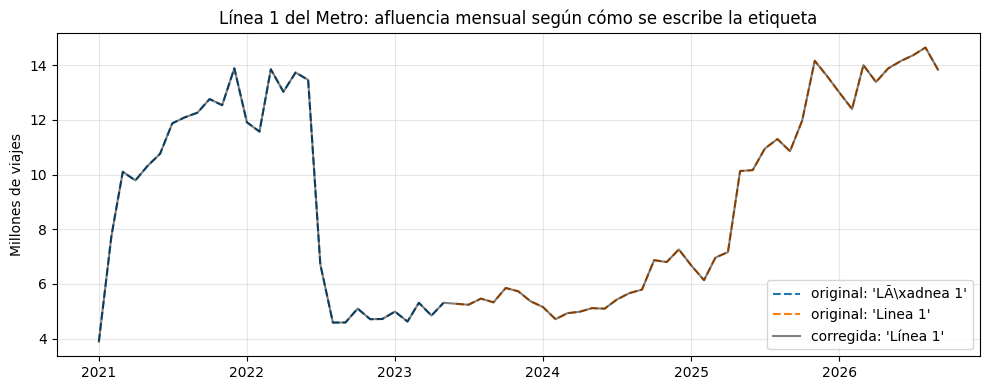

In [70]:
# Consecuencia: serie mensual de la Línea 1 con las etiquetas originales vs. corregidas
original = metro_raw.assign(mes_ = pd.to_datetime(metro_raw["fecha"]).dt.to_period("M"))
corregida = metro.assign(mes_ = pd.to_datetime(metro["fecha"]).dt.to_period("M"))

fig, ax = plt.subplots(figsize=(10, 4))
etiquetas_l1 = [e for e in original["linea"].unique() if clave_sin_acentos(reparar_mojibake(e)) == "linea 1"]
for e in etiquetas_l1:
    s = original[original["linea"] == e].groupby("mes_")["afluencia"].sum() / 1e6
    ax.plot(s.index.to_timestamp(), s.values, "--", label=f"original: {e!r}")
s = corregida[corregida["linea"] == "Línea 1"].groupby("mes_")["afluencia"].sum() / 1e6
ax.plot(s.index.to_timestamp(), s.values, color="black", lw=1.5, alpha=.5, label="corregida: 'Línea 1'")
ax.set_title("Línea 1 del Metro: afluencia mensual según cómo se escribe la etiqueta")
ax.set_ylabel("Millones de viajes"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D1_etiquetas_linea1.png", dpi=150); plt.show()

In [71]:
metro["fecha"] = pd.to_datetime(metro["fecha"], format="%Y-%m-%d")

estacion_dia = metro.groupby(["fecha", "linea", "estacion"], as_index=False)["afluencia"].sum()
estacion_dia["en_servicio"] = estacion_dia["afluencia"] > 0
print(f"Estación-día con afluencia total 0: {(~estacion_dia['en_servicio']).sum():,} "
      f"de {len(estacion_dia):,} ({100 * (~estacion_dia['en_servicio']).mean():.1f} %)")

# Periodos en que una LÍNEA completa suma cero
linea_dia = metro.groupby(["fecha", "linea"])["afluencia"].sum().reset_index()
cerradas = linea_dia[linea_dia["afluencia"] == 0]
resumen_cierres = cerradas.groupby("linea")["fecha"].agg(dias="count", desde="min", hasta="max")
display(resumen_cierres)

# Estaciones con más días en cero
display(estacion_dia[~estacion_dia["en_servicio"]]
        .groupby(["linea", "estacion"]).size().sort_values(ascending=False).head(10)
        .to_frame("dias_en_cero"))

Estación-día con afluencia total 0: 29,764 de 409,305 (7.3 %)


,dias,desde,hasta
linea,,,
Línea 1,16,2021-01-09,2021-01-24
Línea 12,621,2021-05-04,2023-01-14
Línea 2,30,2021-01-09,2021-02-07
Línea 3,23,2021-01-09,2021-01-31
Línea 4,3,2021-01-09,2021-01-11
Línea 5,3,2021-01-09,2021-01-11
Línea 6,3,2021-01-09,2021-01-11


dias_en_cero
linea    estacion                        
Línea 12 Tlaltenco                   1000
         Zapotitlán                   999
         Nopalera                     998
         Olivos                       997
         Tezonco                      995
         Tláhuac                      989
Línea 1  Isabel la Católica           813
         Salto del Agua               813
Línea 12 Periférico Oriente           805
         Lomas Estrella               805

In [72]:
# Sensibilidad: afluencia diaria promedio por estación, con y sin días sin servicio
con = estacion_dia.groupby("linea")["afluencia"].agg(media_con_ceros="mean", mediana_con_ceros="median")
sin = (estacion_dia[estacion_dia["en_servicio"]].groupby("linea")["afluencia"]
       .agg(media_en_servicio="mean", mediana_en_servicio="median"))
pct = (~estacion_dia["en_servicio"]).groupby(estacion_dia["linea"]).mean().mul(100).rename("pct_dias_sin_servicio")
sens = pd.concat([con, sin, pct], axis=1).round(1)
sens["cambio_media_%"] = (100 * (sens["media_en_servicio"] / sens["media_con_ceros"] - 1)).round(1)
sens = sens.sort_values("pct_dias_sin_servicio", ascending=False)
display(sens)
sens.to_csv(OUT_TAB / "D2_sensibilidad_ceros_metro.csv")

# Marcamos la bandera en la tabla a nivel fila (no se borra nada)
metro = metro.merge(estacion_dia[["fecha", "linea", "estacion", "en_servicio"]],
                    on=["fecha", "linea", "estacion"], how="left", validate="many_to_one")

log_decision("D2", "metro", "afluencia",
             "estación-día con afluencia total 0 = sin servicio (cierres L12, incendio ene-2021, obras L1)",
             (~metro["en_servicio"]).sum(),
             "conservar filas y crear bandera en_servicio; promedios 'típicos' solo con en_servicio=True",
             "una estación abierta con 0 accesos reales sería clasificada como cerrada")

,media_con_ceros,mediana_con_ceros,media_en_servicio,mediana_en_servicio,pct_dias_sin_servicio,cambio_media_%
linea,,,,,,
Línea 12,9074.6,6611.5,14434.3,11685.0,37.1,59.1
Línea 1,14549.6,14169.5,19961.1,18153.0,27.1,37.2
Línea 9,19333.0,12505.5,19988.4,12960.5,3.3,3.4
Línea 2,21085.8,17118.5,21593.3,17395.5,2.4,2.4
Línea 3,20789.0,15761.0,21040.0,15879.0,1.2,1.2
Línea 7,14868.0,11853.0,14939.7,11927.0,0.5,0.5
Línea 4,6376.9,5428.5,6386.6,5436.0,0.2,0.2
Línea 5,11622.3,6725.0,11638.9,6733.5,0.1,0.1
Línea 6,8849.4,6987.0,8862.5,6996.0,0.1,0.1


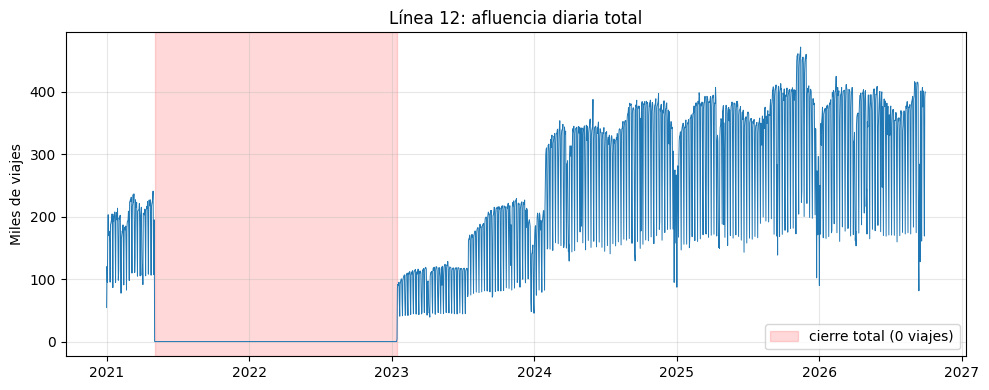

In [73]:
fig, ax = plt.subplots(figsize=(10, 4))
s = linea_dia[linea_dia["linea"] == "Línea 12"].set_index("fecha")["afluencia"] / 1e3
ax.plot(s.index, s.values, lw=.7)
ax.axvspan(pd.Timestamp("2021-05-04"), pd.Timestamp("2023-01-14"), alpha=.15, color="red",
           label="cierre total (0 viajes)")
ax.set_title("Línea 12: afluencia diaria total")
ax.set_ylabel("Miles de viajes"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D2_ceros_linea12.png", dpi=150); plt.show()

In [74]:
llave_ing = ["fecha", "linea", "tipo_ingreso"]
display(ingresos[ingresos.duplicated(llave_ing, keep=False)]
        .sort_values(llave_ing).head(6))

# 1) Duplicados exactos
n_dup = ingresos.duplicated().sum()
ingresos = ingresos.drop_duplicates()
log_decision("D3", "ingresos", "todas", "duplicado exacto (carga repetida 2022-08-31)",
             n_dup, "eliminar copia", "ninguna: la fila es idéntica")

# 2) Conflicto en la llave: conservar el registro distinto de cero
conflicto = ingresos.duplicated(llave_ing, keep=False)
n_conf = conflicto.sum()
ingresos = (ingresos.sort_values("ingreso", ascending=False, na_position="last")
                    .drop_duplicates(llave_ing, keep="first")
                    .sort_values(llave_ing).reset_index(drop=True))
log_decision("D3", "ingresos", "ingreso", "misma llave con dos valores (14,435 vs 0) dentro del bloque repetido",
             n_conf, "conservar el valor distinto de 0",
             "supone que el 0 viene de la carga repetida; afecta 1 día de 1 línea")

print("Duplicados restantes en la llave:", ingresos.duplicated(llave_ing).sum())

,fecha,tipo_ingreso,linea,ingreso
143892,2022-08-31,QR/Validación,Línea 1,0.0
143904,2022-08-31,QR/Validación,Línea 1,0.0
143903,2022-08-31,QR/Validación,Línea 12,0.0
143915,2022-08-31,QR/Validación,Línea 12,0.0
143893,2022-08-31,QR/Validación,Línea 2,0.0
143905,2022-08-31,QR/Validación,Línea 2,0.0


Duplicados restantes en la llave: 0


In [75]:
# 3) Mecanismo de los faltantes: ¿al azar o concentrados?
ingresos["fecha"] = pd.to_datetime(ingresos["fecha"], format="%Y-%m-%d")
ingresos["falta_ingreso"] = ingresos["ingreso"].isna()
faltantes = ingresos[ingresos["falta_ingreso"]]
display(faltantes.groupby([faltantes["fecha"].dt.year.rename("anio"), "linea", "tipo_ingreso"])["fecha"]
        .agg(registros="count", desde="min", hasta="max"))

# ¿Qué reportó la Línea 12 en los meses vecinos al bloque de 2022?
l12 = ingresos[(ingresos["linea"] == "Línea 12") &
               ingresos["fecha"].between("2021-05-01", "2023-02-28")]
display(l12.groupby(l12["fecha"].dt.to_period("M"))["ingreso"]
        .agg(suma="sum", registros="count", faltantes=lambda x: x.isna().sum()).T)

registros      desde      hasta
anio linea    tipo_ingreso                                  
2012 Línea 12 Boletos              305 2012-01-01 2012-10-31
              Recargas             305 2012-01-01 2012-10-31
              Tarjetas             305 2012-01-01 2012-10-31
2022 Línea 12 QR/Validación         92 2022-03-01 2022-07-31
              Tarjetas              60 2022-03-01 2022-06-29

fecha,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11,2021-12,2022-01,2022-02,...,2022-05,2022-06,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02
suma,2703062.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.535660e+06,1.167442e+07
registros,93.0,90.0,93.0,93.0,90.0,93.0,120.0,124.0,124.0,112.0,...,124.0,61.0,93.0,124.0,120.0,124.0,120.0,124.0,1.240000e+02,1.120000e+02
faltantes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,59.0,31.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00


In [76]:
ingresos["motivo_faltante"] = np.select(
    [ingresos["falta_ingreso"] & (ingresos["fecha"].dt.year == 2012),
     ingresos["falta_ingreso"]],
    ["Línea 12 aún no inaugurada", "Línea 12 cerrada"],
    default="",
)
display(ingresos["motivo_faltante"].value_counts())

log_decision("D3", "ingresos", "ingreso",
             "100 % de los faltantes son de L12: antes de su apertura (2012) o durante su cierre (2022)",
             ingresos["falta_ingreso"].sum(),
             "no imputar; columna motivo_faltante; excluir cierres de L12 en comparaciones por línea",
             "no distingue entre 'no hubo ingreso' y 'no se registró', aunque el contexto indica lo primero")

motivo_faltante
                              158869
Línea 12 aún no inaugurada       915
Línea 12 cerrada                 152
Name: count, dtype: int64

In [77]:
print(ecobici["Genero_Usuario"].value_counts(dropna=False))

# Género: categoría explícita en lugar de imputar con la moda
n_gen = (~ecobici["Genero_Usuario"].isin(["M", "F", "O"])).sum()
ecobici["genero"] = ecobici["Genero_Usuario"].map(
    {"M": "Masculino", "F": "Femenino", "O": "Otro"}).fillna("No especificado")
log_decision("D4", "ecobici", "Genero_Usuario", "'?' y faltante = el usuario no reportó género",
             n_gen, "categoría explícita 'No especificado' (no imputar con la moda)",
             "las proporciones por género se calculan con y sin esta categoría")

print("\nComparación: si imputáramos con la moda ('M'), la proporción masculina pasaría de",
      f"{(ecobici['genero'] == 'Masculino').mean():.1%} a",
      f"{((ecobici['genero'] == 'Masculino') | (ecobici['genero'] == 'No especificado')).mean():.1%}")

Genero_Usuario
M      1029960
F       418009
?        49853
O        27479
NaN          1
Name: count, dtype: int64

Comparación: si imputáramos con la moda ('M'), la proporción masculina pasaría de 67.5% a 70.8%


In [78]:
# Edad: faltantes y extremos
edad = ecobici["Edad_Usuario"]
q1, q3 = edad.quantile([.25, .75]); ric = q3 - q1
lim_sup = q3 + 1.5 * ric
print(f"Faltantes: {edad.isna().sum()} | Q1={q1:.0f}, Q3={q3:.0f}, RIC={ric:.0f}, límite IQR superior={lim_sup:.0f}")
print(f"Por encima del límite IQR: {(edad > lim_sup).sum():,} ({(edad > lim_sup).mean():.2%})")
print(f"Mayores de 80: {(edad > 80).sum()} | distribución de los mayores de 90:",
      edad[edad > 90].value_counts().to_dict())

ecobici["edad_atipica"] = edad > 90
ecobici["rango_edad"] = pd.cut(edad, bins=[15, 24, 34, 44, 54, 64, 100],
                               labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"])

log_decision("D4", "ecobici", "Edad_Usuario", "faltantes (79)", edad.isna().sum(),
             "no imputar; quedan fuera solo de los análisis por edad", "pérdida mínima (<0.01 %)")
log_decision("D4", "ecobici", "Edad_Usuario",
             "IQR marca muchos adultos mayores legítimos; >90 años concentrado en 96 y 100",
             ecobici["edad_atipica"].sum(),
             "conservar; bandera edad_atipica; rangos de edad con pd.cut",
             "96 y 100 parecen valores por defecto del registro, pero no es confirmable")

Faltantes: 79 | Q1=28, Q3=40, RIC=12, límite IQR superior=58
Por encima del límite IQR: 43,117 (2.83%)
Mayores de 80: 262 | distribución de los mayores de 90: {96.0: 12, 100.0: 6}


In [79]:
# Duración del viaje (variable derivada)
retiro = pd.to_datetime(ecobici["Fecha_Retiro"] + " " + ecobici["Hora_Retiro"], format="%d/%m/%Y %H:%M:%S")
arribo = pd.to_datetime(ecobici["Fecha_Arribo"] + " " + ecobici["Hora_Arribo"], format="%d/%m/%Y %H:%M:%S")
ecobici["fecha_retiro"] = retiro
ecobici["duracion_min"] = (arribo - retiro).dt.total_seconds() / 60

print(ecobici["duracion_min"].describe(percentiles=[.5, .9, .99, .999]).round(1))
print("Duración negativa:", (ecobici["duracion_min"] < 0).sum(),
      "| > 3 h:", (ecobici["duracion_min"] > 180).sum(),
      "| > 24 h:", (ecobici["duracion_min"] > 1440).sum())
print("Viajes retirados antes de enero 2026:", (retiro < "2026-01-01").sum(),
      "| el más antiguo:", retiro.min())

count    1525302.0
mean          15.7
std          275.8
min            0.2
50%           11.8
90%           30.2
99%           50.0
99.9%        108.4
max       257146.3
Name: duracion_min, dtype: float64
Duración negativa: 0 | > 3 h: 574 | > 24 h: 31
Viajes retirados antes de enero 2026: 105 | el más antiguo: 2025-08-02 23:24:30


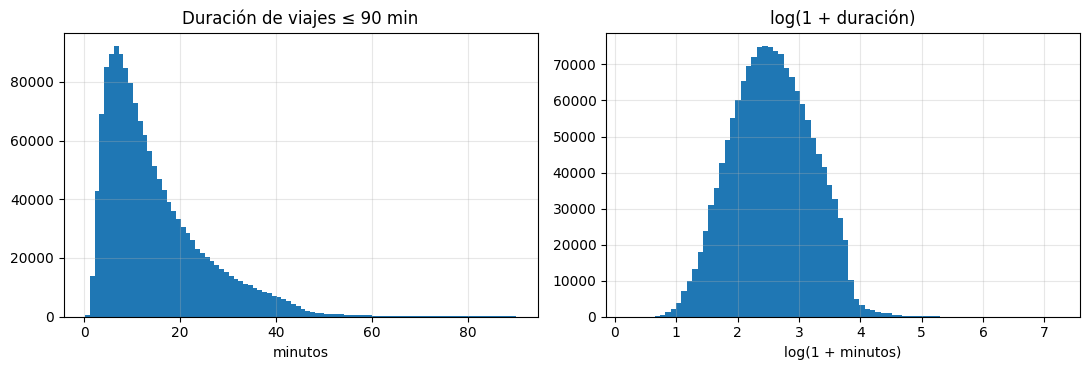

Viajes válidos para el análisis de enero: 1,525,178 de 1,525,302


In [80]:
# Error confirmable vs. atípico plausible
ecobici["duracion_imposible"] = ecobici["duracion_min"] > 1440     # bici fuera más de un día
ecobici["fuera_de_periodo"] = ecobici["fecha_retiro"] < "2026-01-01"

log_decision("D4", "ecobici", "duracion_min", "> 24 h: no es un viaje sino una bici no devuelta o error de cierre",
             ecobici["duracion_imposible"].sum(), "excluir de análisis de duración (bandera duracion_imposible)",
             "algún viaje real muy largo podría quedar fuera")
log_decision("D4", "ecobici", "Fecha_Retiro", "viajes retirados antes de 2026-01-01 que cerraron en enero",
             ecobici["fuera_de_periodo"].sum(), "excluir del análisis de enero (bandera fuera_de_periodo)",
             "el viaje de fin de año que cruza la medianoche del 31 de diciembre queda fuera")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = ecobici.loc[~ecobici["duracion_imposible"], "duracion_min"]
axes[0].hist(d[d <= 90], bins=90)
axes[0].set_title("Duración de viajes ≤ 90 min"); axes[0].set_xlabel("minutos")
axes[1].hist(np.log1p(d), bins=80)
axes[1].set_title("log(1 + duración)"); axes[1].set_xlabel("log(1 + minutos)")
for a in axes: a.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT_FIG / "D4_duracion_ecobici.png", dpi=150); plt.show()

print(f"Viajes válidos para el análisis de enero: "
      f"{(~ecobici['duracion_imposible'] & ~ecobici['fuera_de_periodo']).sum():,} de {len(ecobici):,}")

In [81]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

def agregar_calendario(df, col_fecha="fecha"):
    df["dia_semana"] = pd.Categorical(df[col_fecha].dt.dayofweek.map(dict(enumerate(DIAS))),
                                      categories=DIAS, ordered=True)
    df["tipo_dia"] = np.where(df[col_fecha].dt.dayofweek >= 5, "Fin de semana", "Laboral")
    return df

metrobus["fecha"] = pd.to_datetime(metrobus["fecha"], format="%Y-%m-%d")
metro = agregar_calendario(metro)
metrobus = agregar_calendario(metrobus)
ecobici = agregar_calendario(ecobici, "fecha_retiro")
ecobici["hora_retiro"] = ecobici["fecha_retiro"].dt.hour

# Metrobús: afluencias no enteras (Línea 4, Prepago, enero 2025)
n_frac = (metrobus["afluencia"] % 1 != 0).sum()
metrobus["afluencia"] = metrobus["afluencia"].round().astype("int64")
log_decision("T", "metrobus", "afluencia", "57 conteos con decimales (L4, Prepago, ene-2025), probablemente estimados",
             n_frac, "redondear al entero", "el valor original pudo ser una estimación de la fuente")

# Afluencia histórica: texto con comas -> número
for col in ["afluencia_tarjeta", "afluencia_boleto", "afluencia_total_preliminar"]:
    historico[col] = pd.to_numeric(historico[col].astype(str).str.replace(",", "", regex=False),
                                   errors="coerce")
historico["fecha"] = pd.to_datetime(historico["fecha"], format="%Y-%m-%d")
log_decision("T", "historico", "afluencia_*", "números guardados como texto con comas de miles",
             len(historico), "convertir a numérico",
             "tarjeta/boleto faltan por estructura en organismos que no los distinguen; no se imputan")

display(historico.dtypes.to_frame("tipo"))

,tipo
id,int64
organismo,object
linea_servicio,object
dia,object
fecha,datetime64[ns]
afluencia_tarjeta,float64
afluencia_boleto,float64
afluencia_total_preliminar,float64


In [82]:
bitacora = pd.DataFrame(registro)
display(bitacora)

bitacora.to_csv(OUT_DATA / "bitacora_limpieza.csv", index=False)
metro.to_csv(OUT_DATA / "metro_limpio.csv.gz", index=False, compression="gzip")
metrobus.to_csv(OUT_DATA / "metrobus_limpio.csv", index=False)
ingresos.to_csv(OUT_DATA / "ingresos_limpio.csv.gz", index=False, compression="gzip")
historico.to_csv(OUT_DATA / "afluencia_historica_limpia.csv", index=False)
cols_eco = ["genero", "Edad_Usuario", "rango_edad", "edad_atipica", "Ciclo_Estacion_Retiro",
            "Ciclo_EstacionArribo", "fecha_retiro", "hora_retiro", "dia_semana", "tipo_dia",
            "duracion_min", "duracion_imposible", "fuera_de_periodo"]
ecobici[cols_eco].to_csv(OUT_DATA / "ecobici_2026_01_limpio.csv.gz", index=False, compression="gzip")

for f in sorted(OUT_DATA.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:6.1f} MB")

,paso,tabla,variable,criterio,filas_afectadas,accion,limitacion
0,D1,metro,linea,mojibake y 'Linea' sin acento según el periodo,1227915,estandarizar a 'Línea X',ninguna: es la misma línea
1,D1,metro,estacion,mojibake y variantes de acentos/mayúsculas,396801,reparar codificación y unificar a la escritura...,la unificación supone que nombres iguales sin ...
2,D1,metrobus,linea,tres escrituras distintas según el periodo,6398,estandarizar a 'Línea X',ninguna
3,D1,ingresos,tipo_ingreso,'QR/Validador' renombrado por la fuente en dic...,2916,unificar en 'QR/Validación',supone que el cambio fue solo de nombre y no d...
4,D2,metro,afluencia,estación-día con afluencia total 0 = sin servi...,89292,conservar filas y crear bandera en_servicio; p...,una estación abierta con 0 accesos reales serí...
5,D3,ingresos,todas,duplicado exacto (carga repetida 2022-08-31),11,eliminar copia,ninguna: la fila es idéntica
6,D3,ingresos,ingreso,"misma llave con dos valores (14,435 vs 0) dent...",2,conservar el valor distinto de 0,supone que el 0 viene de la carga repetida; af...
7,D3,ingresos,ingreso,100 % de los faltantes son de L12: antes de su...,1067,no imputar; columna motivo_faltante; excluir c...,no distingue entre 'no hubo ingreso' y 'no se ...
8,D4,ecobici,Genero_Usuario,'?' y faltante = el usuario no reportó género,49854,categoría explícita 'No especificado' (no impu...,las proporciones por género se calculan con y ...
9,D4,ecobici,Edad_Usuario,faltantes (79),79,no imputar; quedan fuera solo de los análisis ...,pérdida mínima (<0.01 %)


afluencia_historica_limpia.csv              1.0 MB
bitacora_limpieza.csv                       0.0 MB
ecobici_2026_01_limpio.csv.gz              20.0 MB
ingresos_limpio.csv.gz                      0.9 MB
metro_limpio.csv.gz                         9.2 MB
metrobus_limpio.csv                         1.9 MB
